# 03 | Histórico sintético por coorte e disciplina

POC semissintética • contrato provisório • sem homologação acadêmica.
Execute em kernel reiniciado, de cima para baixo. As credenciais vêm do ambiente.


**Objetivo:** gerar histórico reproduzível condicionado à estrutura importada. **Entradas:** seed42, cenário baseline, ciclos2022-1 a2024-1; alvo2024-2. **Esperado:** snapshot SQL imutável, planejado separado de sintético.

In [1]:
import os, json
import pandas as pd
from IPython.display import display, Markdown
from src.workbench.application_client import call, context, save_context

from pathlib import Path
from src.academic.importer import import_sources
from src.simulation.academic import simulate
from src.simulation.store import save
SEED=42
CENARIO='baseline'
snapshot=simulate(import_sources(Path('/reference')),seed=SEED,profile=CENARIO)
save(snapshot)
save_context(snapshot_id=snapshot['snapshot_id'])
display({k:snapshot[k] for k in ('snapshot_id','dataset_sha256','scenario_id','history_window','target','data_completeness')})


{'snapshot_id': '9158d4db-c80b-5638-8aa0-9467c60f6107',
 'dataset_sha256': '721b8d6ded6550a3b0f66cdfba9749c1f1bf93d9cd1aa62f70ad3355b15dd6fa',
 'scenario_id': 'baseline',
 'history_window': ['2022-1', '2024-1'],
 'target': '2024-2',
 'data_completeness': 'REFERENCE_STRUCTURE_WITH_SYNTHETIC_COHORTS'}

**Executar:** observar regulares e adicionais por ciclo. **Resultado:** linha temporal SYNTHETIC_HISTORY; alvo futuro não entra no treino.

,course_code,split,observações
0,2248,FUTURE,16
1,2248,HISTORY,66
2,2287,FUTURE,23
3,2287,HISTORY,77
4,2348,FUTURE,19
5,2348,HISTORY,84


,cycle_code,cohort_id,discipline_code,regular,dependency,elective,split
151,2024-1,f281c426-84eb-5a05-9e16-62ded919eb15,PSE106A,54,2,0,HISTORY
152,2024-2,05e82e16-5175-5f58-9180-24898cababea,PSE106A,47,2,0,FUTURE
198,2024-1,f281c426-84eb-5a05-9e16-62ded919eb15,PCO137A,54,4,0,HISTORY
199,2024-2,05e82e16-5175-5f58-9180-24898cababea,PCO137A,47,6,0,FUTURE
214,2024-1,f281c426-84eb-5a05-9e16-62ded919eb15,PSE114A,54,6,2,HISTORY
215,2024-2,05e82e16-5175-5f58-9180-24898cababea,PSE114A,47,7,0,FUTURE
222,2024-1,f281c426-84eb-5a05-9e16-62ded919eb15,PCP113A,54,8,0,HISTORY
223,2024-2,05e82e16-5175-5f58-9180-24898cababea,PCP113A,47,4,0,FUTURE
257,2024-1,f281c426-84eb-5a05-9e16-62ded919eb15,PSI121A,54,4,0,HISTORY
258,2024-2,05e82e16-5175-5f58-9180-24898cababea,PSI121A,47,4,0,FUTURE


<Axes: title={'center': 'Médias DEMO por disciplina — não matrícula real'}, xlabel='cycle_code'>

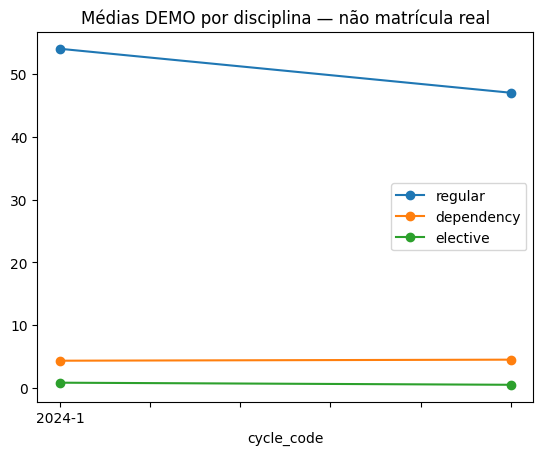

In [2]:

from src.workbench.academic_data import load
frame,_=load(snapshot['snapshot_id'])
display(frame.groupby(['course_code','split']).size().rename('observações').reset_index())
cyber=frame[(frame.course_code=='2287') & (frame.period==2)]
display(cyber[['cycle_code','cohort_id','discipline_code','regular','dependency','elective','split']].tail(12))
cyber.groupby('cycle_code')[['regular','dependency','elective']].mean().plot(marker='o',title='Médias DEMO por disciplina — não matrícula real')


**Onde conferir:** [MLflow](http://localhost:5000), [RustFS](http://localhost:9001), [API](http://localhost:8000/docs), [Logs](http://localhost:8088). Em falha: `docker compose logs --tail 100 api inference worker mlflow`.